# 06. SOTA: Wave-SVM

## Ý tưởng cần code: Wave-SVM không có bài toán đối ngẫu dễ giải (vì loss không lồi), nên tác giả giải thẳng bài toán gốc bằng Adam – thuật toán gradient dùng trong deep learning. Ta cần ba thứ: hàm wave loss, đạo hàm của nó, và vòng lặp Adam

$$
L(u)=\frac{1}{\lambda}
\left(
1-\frac{1}{1+\lambda u^2 e^{au}}
\right)
$$

$$
L'(u)=
\frac{u e^{au}(2+au)}
{\left(1+\lambda u^2 e^{au}\right)^2}
$$

## Import và vẽ 4 hàm mất mát

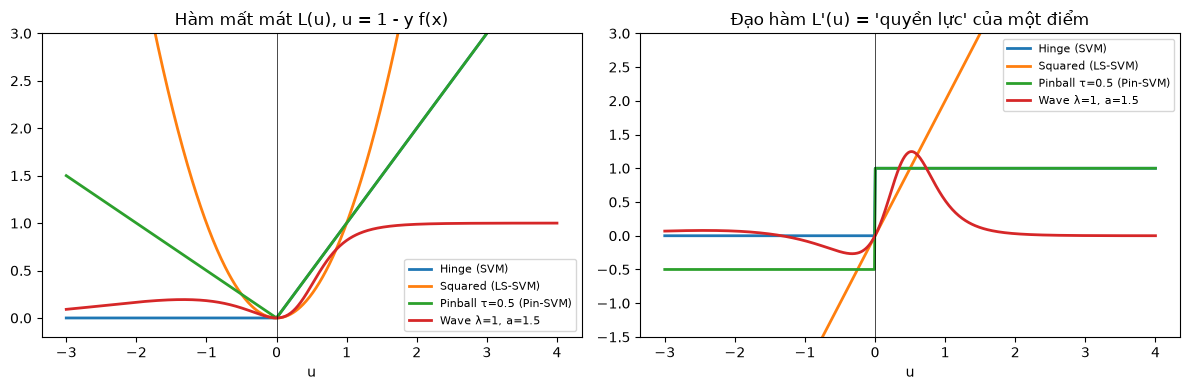

In [8]:
import sys, json
sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.tools import load_features, tune_walk_forward, evaluate_on_test, summarize, train_test, scores
from src.models import WaveSVM, wave_loss, wave_grad
from src.wave_svm_official import wave_adam_official

data = load_features()
u = np.linspace(-3, 4, 600)
L = {"Hinge (SVM)": np.maximum(0, u), "Squared (LS-SVM)": u ** 2,
     "Pinball τ=0.5 (Pin-SVM)": np.where(u > 0, u, -0.5 * u), "Wave λ=1, a=1.5": wave_loss(u, 1, 1.5)}
dL = {"Hinge (SVM)": (u > 0).astype(float), "Squared (LS-SVM)": 2 * u,
      "Pinball τ=0.5 (Pin-SVM)": np.where(u > 0, 1, -0.5), "Wave λ=1, a=1.5": wave_grad(u, 1, 1.5)}
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name in L:
    ax[0].plot(u, L[name], label=name, lw=2)
    ax[1].plot(u, dL[name], label=name, lw=2)
ax[0].set_ylim(-0.2, 3); ax[1].set_ylim(-1.5, 3)
ax[0].set_title("Hàm mất mát L(u), u = 1 - y f(x)"); ax[1].set_title("Đạo hàm L'(u) = 'quyền lực' của một điểm")
for a_ in ax:
    a_.axvline(0, color="k", lw=.5); a_.set_xlabel("u"); a_.legend(fontsize=8)
plt.tight_layout()
fig.savefig("../reports/figures/fig_losses.png", dpi=150, bbox_inches="tight")

## Kiểm tra đạo hàm bằng sai phân hữu hạn

In [9]:
h = 1e-6
numeric = (wave_loss(u + h, 1, 1.5) - wave_loss(u - h, 1, 1.5)) / (2 * h)     # đạo hàm số
e = np.exp(1.5 * u)
paper_formula = u * e * (2 + u) / (1 + u ** 2 * e) ** 2                      # công thức (2+u) trong bài báo
print("Sai số lớn nhất - công thức (2+au):", np.abs(numeric - wave_grad(u, 1, 1.5)).max())
print("Sai số lớn nhất - công thức (2+u) :", np.abs(numeric - paper_formula).max())

Sai số lớn nhất - công thức (2+au): 1.1003417621502365e-10
Sai số lớn nhất - công thức (2+u) : 0.12499446434697403


## Chạy mã gốc so với bản theo bài báo

In [10]:
X_train, y_train, X_test, y_test, *_ = train_test(data)
rows_off = []
for s in range(10):
    score, _ = wave_adam_official(X_train, y_train, X_test, a=1.5, b=1.0, C=1.0, mew=1.0, m=32, seed=s)
    rows_off.append({"model": "Wave-SVM (mã gốc, port nguyên trạng)", "seed": s,
                     **scores(y_test, np.where(score >= 0, 1, -1), score)})
    m = WaveSVM(C=1.0, lam=1.0, a=1.5, kernel="rbf", gamma=1 / (2 * 1.0 ** 2), k=32, seed=s,
                balanced=False).fit(X_train, y_train)
    dec = m.decision_function(X_test)
    rows_off.append({"model": "Wave-SVM (theo bài báo, cùng tham số)", "seed": s,
                     **scores(y_test, np.where(dec >= 0, 1, -1), dec)})
off = pd.DataFrame(rows_off)
off.to_csv("../reports/tables/wave_official_vs_paper.csv", index=False)
summarize(off, ["Accuracy", "BalAcc", "AUC", "UpRate"])

,Accuracy,BalAcc,AUC,UpRate
model,,,,
"Wave-SVM (mã gốc, port nguyên trạng)",0.4217,0.5000,0.5159 ± 0.0043,0.0000
"Wave-SVM (theo bài báo, cùng tham số)",0.5573 ± 0.0351,0.5022 ± 0.0102,0.4877 ± 0.0137,0.8523 ± 0.2449


## Chọn tham số và đánh giá

In [11]:
GRID = [
    {"kernel": ["linear"], "C": [0.01, 0.1, 1, 10], "a": [0.5, 1.0, 1.5, 2.0], "lam": [0.5, 1.0, 2.0],
     "k": [32, 256]},
    {"kernel": ["rbf"], "C": [0.1, 1, 10], "a": [0.5, 1.5], "lam": [1.0], "gamma": [0.01, 0.05, 0.2],
     "k": [32, 256]},
]
best, rows = tune_walk_forward(WaveSVM, GRID, data.loc[:"2022"])     # khoảng 2-3 phút
json.dump({"best": best, "rows": rows}, open("../reports/tables/tuning_Wave-SVM.json", "w"), indent=1)
print("Tham số tốt nhất:", best)
pd.DataFrame([{**r["params"], "BalAcc_val": r["BalAcc"], "std": r["std"]} for r in rows]) \
  .sort_values("BalAcc_val", ascending=False).head(8)

Tham số tốt nhất: {'kernel': 'rbf', 'C': 0.1, 'a': 0.5, 'lam': 1.0, 'gamma': 0.2, 'k': 32}


,kernel,C,a,lam,k,BalAcc_val,std,gamma
100,rbf,0.10,0.5,1.0,32,0.528183,0.010658,0.2
70,linear,1.00,2.0,2.0,32,0.522435,0.029492,NaN
0,linear,0.01,0.5,0.5,32,0.521475,0.028418,NaN
6,linear,0.01,1.0,0.5,32,0.521246,0.023184,NaN
30,linear,0.10,1.0,0.5,32,0.520035,0.043208,NaN
86,linear,10.00,1.5,1.0,32,0.518682,0.037263,NaN
19,linear,0.01,2.0,0.5,256,0.518176,0.033953,NaN
41,linear,0.10,1.5,2.0,256,0.518080,0.025251,NaN


## Đánh giá trên test

In [12]:
res = evaluate_on_test("Wave-SVM", WaveSVM, best, data, seeds=range(10))
res.to_csv("../reports/tables/test_Wave-SVM.csv", index=False)
summarize(res, ["Accuracy", "BalAcc", "F1", "AUC", "MCC", "UpRate", "time_s", "nonzero"])

,Accuracy,BalAcc,F1,AUC,MCC,UpRate,time_s,nonzero
model,,,,,,,,
Wave-SVM,0.4925 ± 0.0709,0.5009 ± 0.0086,0.3784 ± 0.3153,0.4971 ± 0.0229,0.0021 ± 0.0450,0.4465 ± 0.4617,0.4767 ± 0.0332,1.0000


## Đồ thị hội tụ và độ nhạy (a, λ)

Giá trị mục tiêu cuối theo seed: [518.4 433.2 515.1 434.5 517.8]


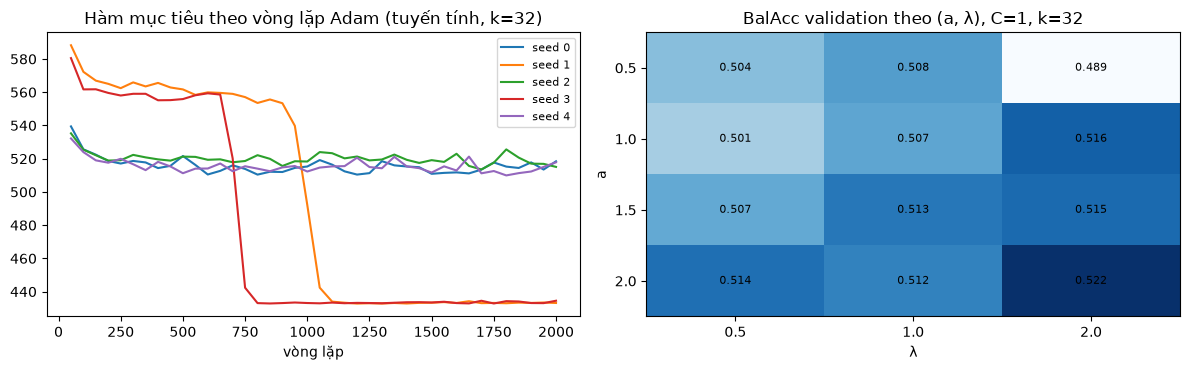

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
linear_rows = [r for r in rows if r["params"]["kernel"] == "linear"]
lin_best = max(linear_rows, key=lambda r: r["BalAcc"])["params"]
final_obj = []
for s in range(5):
    m = WaveSVM(**lin_best, seed=s, max_iter=2000, tol=0).fit(X_train, y_train)
    t, f = zip(*m.history_)
    ax[0].plot(t, f, label=f"seed {s}")
    final_obj.append(f[-1])
ax[0].set_title(f"Hàm mục tiêu theo vòng lặp Adam (tuyến tính, k={lin_best['k']})")
ax[0].set_xlabel("vòng lặp"); ax[0].legend(fontsize=8)
print("Giá trị mục tiêu cuối theo seed:", np.round(final_obj, 1))

same = [r for r in linear_rows if r["params"]["C"] == lin_best["C"] and r["params"]["k"] == lin_best["k"]]
H = pd.DataFrame([{"a": r["params"]["a"], "lam": r["params"]["lam"], "BalAcc": r["BalAcc"]} for r in same]) \
      .pivot(index="a", columns="lam", values="BalAcc")
ax[1].imshow(H.values, cmap="Blues", aspect="auto")
ax[1].set_xticks(range(H.shape[1]), H.columns); ax[1].set_yticks(range(H.shape[0]), H.index)
ax[1].set_xlabel("λ"); ax[1].set_ylabel("a")
ax[1].set_title(f"BalAcc validation theo (a, λ), C={lin_best['C']}, k={lin_best['k']}")
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        ax[1].text(j, i, f"{H.values[i, j]:.3f}", ha="center", va="center", fontsize=8)
plt.tight_layout()
fig.savefig("../reports/figures/fig_wave_convergence_sensitivity.png", dpi=150, bbox_inches="tight")